In [1]:
import signalTreatment as st
import splitSignal as ss
import dataSorting as ds
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import os
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from prettytable import PrettyTable

In [2]:
import dataSorting as ds
from confusionMatrix import ConfusionMatrix

In [3]:
def get_file_names_from_directory(directory):
    return [f for f in os.listdir(directory) if ds.parseFileName(f)[0]!="Strasser"]

def get_file_names():
    l1 = get_file_names_from_directory("signaux EEG")
    l2 = get_file_names_from_directory("signaux EEG Prisha")
    l = [*l1, *l2]
    return l

In [4]:
def get_all_data_and_labels():
    X, y = np.array([]), np.array([]) 
    file_names = get_file_names()
    for i in range(len(file_names)):
        try:
            X_file, y_file = ds.getDataAndLabels(file_names[i])
        except:
            print(file_names[i])
        if i == 0:
            X, y = X_file, y_file
        else:
            X =np.vstack((X, X_file))
            y = np.vstack((y, y_file))
    return X, y




In [5]:
# fileName = "Chandiramani_Prisha_Congruent_1.xdf"
# X, y = ds.getDataAndLabels(fileName)

X, y = get_all_data_and_labels()
print(X.shape, y.shape)
X_flat = X.reshape(X.shape[0], -1)

y_labels = np.argmax(y, axis=1) 





(3222, 36, 64) (3222, 3)


[[ 33.  20.   1.]
 [134. 656.  96.]
 [  0.  22.   5.]]
the model accuracy is  0.717683557394002
+---+-----------+--------+-------------+---------+
|   | Precision | Recall | Specificity | F1score |
+---+-----------+--------+-------------+---------+
| 0 |   0.611   | 0.198  |    0.974    |    0    |
| 1 |    0.74   |  0.94  |    0.145    |    1    |
| 2 |   0.185   | 0.049  |    0.975    |    0    |
+---+-----------+--------+-------------+---------+


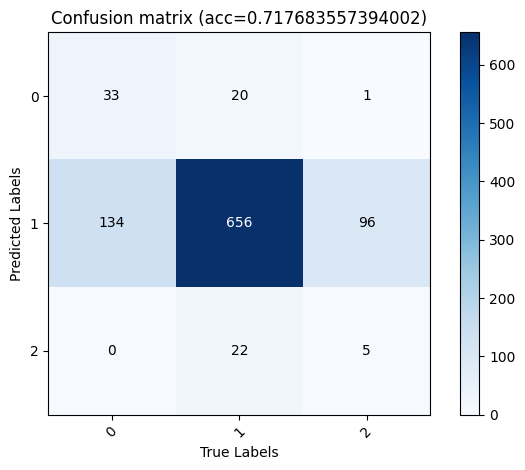

[[ 402.    0.    0.]
 [   0. 1559.    0.]
 [   0.    0.  294.]]
the model accuracy is  1.0
+---+-----------+--------+-------------+---------+
|   | Precision | Recall | Specificity | F1score |
+---+-----------+--------+-------------+---------+
| 0 |    1.0    |  1.0   |     1.0     |    1    |
| 1 |    1.0    |  1.0   |     1.0     |    1    |
| 2 |    1.0    |  1.0   |     1.0     |    1    |
+---+-----------+--------+-------------+---------+


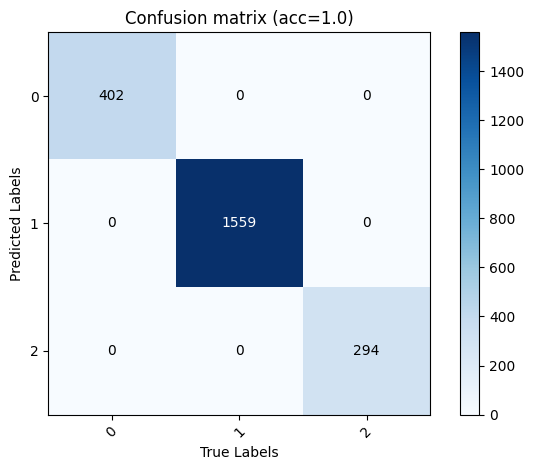

In [14]:

from sklearn.model_selection import train_test_split

# Diviser les données
X_train, X_test, y_train, y_test = train_test_split(X_flat, y_labels, test_size=0.3, random_state=42)

# Initialiser le classifieur
clf = RandomForestClassifier(n_estimators=50, random_state=42)

# Entraîner le modèle
clf.fit(X_train, y_train)



import matplotlib.pyplot as plt
confusion_1 = ConfusionMatrix(labels=['0','1','2'])
confusion_1.update(clf.predict(X_test), y_test)
confusion_1.plot()

confusion_2 = ConfusionMatrix(labels=['0','1','2'])
confusion_2.update(clf.predict(X_train), y_train)
confusion_2.plot()